In [21]:
import numpy as np
import  pandas as pd
import matplotlib.pyplot as plt

In [ ]:
df = pd.read_csv("Car_Detail.csv")
df

,Make,Type,Origin,DriveTrain,EngineSize,Cylinders,Horsepower,MPG_City,MPG_Highway,Weight,Wheelbase,Length,MSRP
0,Acura,SUV,Asia,All,3.5,6.0,265,17,23,4451,106,189,36945
1,Acura,Sedan,Asia,Front,2.0,4.0,200,24,31,2778,101,172,23820
2,Acura,Sedan,Asia,Front,2.4,4.0,200,22,29,3230,105,183,26990
3,Acura,Sedan,Asia,Front,3.2,6.0,270,20,28,3575,108,186,33195
4,Acura,Sedan,Asia,Front,3.5,6.0,225,18,24,3880,115,197,43755
...,...,...,...,...,...,...,...,...,...,...,...,...,...
423,Volvo,Sedan,Europe,Front,2.4,5.0,197,21,28,3450,105,186,40565
424,Volvo,Sedan,Europe,Front,2.3,5.0,242,20,26,3450,105,186,42565
425,Volvo,Sedan,Europe,Front,2.9,6.0,268,19,26,3653,110,190,45210
426,Volvo,Wagon,Europe,Front,1.9,4.0,170,22,29,2822,101,180,26135


Create a linear regression to predict the MSRP

firstly we check data description and information

In [23]:
df.describe()

,EngineSize,Cylinders,Horsepower,MPG_City,MPG_Highway,Weight,Wheelbase,Length,MSRP
count,428.000000,426.000000,428.000000,428.000000,428.000000,428.000000,428.000000,428.000000,428.000000
mean,3.196729,5.807512,215.885514,20.060748,26.843458,3577.953271,108.154206,186.362150,32774.855140
std,1.108595,1.558443,71.836032,5.238218,5.741201,758.983215,8.311813,14.357991,19431.716674
min,1.300000,3.000000,73.000000,10.000000,12.000000,1850.000000,89.000000,143.000000,10280.000000
25%,2.375000,4.000000,165.000000,17.000000,24.000000,3104.000000,103.000000,178.000000,20334.250000
50%,3.000000,6.000000,210.000000,19.000000,26.000000,3474.500000,107.000000,187.000000,27635.000000
75%,3.900000,6.000000,255.000000,21.250000,29.000000,3977.750000,112.000000,194.000000,39205.000000
max,8.300000,12.000000,500.000000,60.000000,66.000000,7190.000000,144.000000,238.000000,192465.000000


In [24]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 428 entries, 0 to 427
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Make         428 non-null    object 
 1   Type         428 non-null    object 
 2   Origin       428 non-null    object 
 3   DriveTrain   428 non-null    object 
 4   EngineSize   428 non-null    float64
 5   Cylinders    426 non-null    float64
 6   Horsepower   428 non-null    int64  
 7   MPG_City     428 non-null    int64  
 8   MPG_Highway  428 non-null    int64  
 9   Weight       428 non-null    int64  
 10  Wheelbase    428 non-null    int64  
 11  Length       428 non-null    int64  
 12  MSRP         428 non-null    int64  
dtypes: float64(2), int64(7), object(4)
memory usage: 43.6+ KB


as we can see Cylinders has 2 nan value

we will fix that by giving the nan value the mean of the column



In [25]:
#convert nan value to mean
#incase of other numercial column get nan as well

#convert all int dtype to float
for c in df.columns:
    if df[c].dtype == np.int64:
        df[c] = df[c].astype(np.float64)

for column in df.columns:
    if df[column].dtype == float and True in np.isnan(df[column]).values:
        #Found column with nan
        
        mean = np.nanmean(df[column].values)
        for i in range(len(df[column])):
            if np.isnan(df[column][i]) == True:
                df.loc[i, column] = mean

In [26]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 428 entries, 0 to 427
Data columns (total 13 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Make         428 non-null    object 
 1   Type         428 non-null    object 
 2   Origin       428 non-null    object 
 3   DriveTrain   428 non-null    object 
 4   EngineSize   428 non-null    float64
 5   Cylinders    428 non-null    float64
 6   Horsepower   428 non-null    float64
 7   MPG_City     428 non-null    float64
 8   MPG_Highway  428 non-null    float64
 9   Weight       428 non-null    float64
 10  Wheelbase    428 non-null    float64
 11  Length       428 non-null    float64
 12  MSRP         428 non-null    float64
dtypes: float64(9), object(4)
memory usage: 43.6+ KB


Dectect and replace outliners with mean again

In [27]:
for column in df.columns:
    if df[column].dtype == float:
        #it is a numercial column
        array = df[column].values
        Median = np.median(array)
        Q1 = np.quantile(array,0.25)
        Q3 = np.quantile(array,0.75)

        IQR = Q3 - Q1
        Lower = Q1 - 1.5*IQR 
        Upper = Q3 + 1.5*IQR

        for i in range(len(array)):
            if array[i] < Lower or array[i] > Upper:
                df.loc[i, column] = Median

Perform encoding for each column

In [28]:
for column in df.columns:
    #numerical

    if df[column].dtype == float:
        # we gonna do stardard scaling
        array = np.array(df[column].values)
        mean = np.mean(array)
        Sd = np.std(array)


        for i in range(len(array)):
            df.loc[i, column] = (array[i] - mean)/Sd

    #catorgical
    if df[column].dtype == object:
        UnquieSet = list(set(df[column].values))

        for i in range(len(df[column])):
            df.loc[i, column] = UnquieSet.index(df[column][i]) + 1

#let not set anything to 0

In [29]:
df

,Make,Type,Origin,DriveTrain,EngineSize,Cylinders,Horsepower,MPG_City,MPG_Highway,Weight,Wheelbase,Length,MSRP
0,38,3,3,3,0.304668,0.176543,0.843180,-0.684036,-0.769251,1.489979,-0.190297,0.254570,0.709500
1,38,2,3,2,-1.103516,-1.217756,-0.182185,1.543543,1.117508,-1.139630,-0.960121,-1.125648,-0.455627
2,38,2,3,2,-0.728000,-1.217756,-0.182185,0.907092,0.645818,-0.429180,-0.344262,-0.232566,-0.174221
3,38,2,3,2,0.023031,0.176543,0.922055,0.270640,0.409973,0.113088,0.117632,0.011002,0.376606
4,38,2,3,2,0.304668,0.176543,0.212186,-0.365811,-0.533406,0.592485,1.195385,0.904084,1.314034
...,...,...,...,...,...,...,...,...,...,...,...,...,...
423,3,2,2,2,-0.728000,-0.520606,-0.229509,0.588866,0.409973,-0.083386,-0.344262,0.011002,1.030852
424,3,2,2,2,-0.821879,-0.520606,0.480359,0.270640,-0.061716,-0.083386,-0.344262,0.011002,1.208395
425,3,2,2,2,-0.258606,0.176543,0.890505,-0.047585,-0.061716,0.235688,0.425561,0.335759,1.443196
426,3,6,2,2,-1.197395,-1.217756,-0.655430,0.907092,0.645818,-1.070472,-0.960121,-0.476133,-0.250121


DAta Split

In [30]:
np.random.seed(42)

In [31]:
X = []
Y = np.array(df['MSRP'].values)

dfClone = df.drop(columns=["MSRP"])
dfTranspose = dfClone.transpose()
for i in dfTranspose.columns:
    X.append(np.array(dfTranspose[i].values))


Pemutation = np.random.permutation(len(Y))
SplitPoint = 1/3
X = np.array(X)

Y_Test,Y_Train = Y[Pemutation][0:int(len(Y)*1/3)],Y[Pemutation][int(len(Y)*1/3):int(len(Y))]
X_Test,X_Train = X[Pemutation][0:int(len(X)*1/3)],X[Pemutation][int(len(X)*1/3):int(len(X))]


In [32]:
def Factorial(n):
    a = 1
    for i in range(1,n+1):
        a *= i
    return a

def totalTerm(n,Dimension):
    return Factorial(n+Dimension)/(Factorial(n) * Factorial(Dimension))

compute ALL term possible base on n-degree and Size of X

In [33]:
def GetUniqueSet(n,XSize):
    SetList = []
    for i in range(1,n+1):
        if i == 1:
            for i2 in range(0,XSize):
                SetList.append([i2])
        else:
            NewSet = []
            for i3 in range(0,len(SetList)):
                for i2 in range(0,XSize):
                    CurrentSet = SetList[i3].copy()
                    CurrentSet.append(i2)
                    NewSet.append(CurrentSet)
                    
            SetList = NewSet


    UniqueList = []
    for i in range(0,len(SetList)):
        SetList[i].sort()
        if not SetList[i] in UniqueList:
            UniqueList.append(SetList[i])

    return UniqueList


def GetPolynomialTermMatrix(x,nDegree):
    FinalPolynomialTermArray = np.array([])

    #loop though all the term each degree

    for n in range(1,nDegree+1):
        array = x #X Data
        NewArray = array[GetUniqueSet(n,len(array))]
        PolynomialTermArray = []
        for i in range(0,len(NewArray)):
            PolynomialTermArray.append(np.prod(NewArray[i]))

        FinalPolynomialTermArray = np.concatenate((FinalPolynomialTermArray,np.array(PolynomialTermArray)))

    return np.array(FinalPolynomialTermArray)

In [34]:
print(len(GetPolynomialTermMatrix(X_Train[1],2)))
print(len(X_Train[1]) )

90
12


In [35]:
epoches = 100
nDegree = 2
Dimension = len(df.columns)-1

co = np.zeros(int(totalTerm(nDegree,Dimension))-1)
Intercept = 0


BatchSize = 60
LearningRate = 0.001

        
        
#n-Degree polynomial        
def lossfunc(co,Intercept,x,y):
    Sum = 0

    for i in range(0,len(y)):
        PolynomialTermArray = GetPolynomialTermMatrix(x[i],nDegree)
        Sum += (y[i] - np.dot(co, PolynomialTermArray) - Intercept)**2

    return Sum / len(y)

#1st degree polynomial
def lossfunc1(co,Intercept,x,y):
    Sum = 0

    for i in range(0,len(y)):
        Sum += (y[i] - np.dot(co, x[i]) - Intercept)**2

    return Sum / len(y)

def DerLossFunc(co,Intercept,x,y):
    h = 0.001
    DerArray = np.zeros(len(co))
    Default = lossfunc(co,Intercept,x,y)
    for i in range(len(co)):
        AddArray = np.zeros(len(co))
        AddArray[i] = h
        DerArray[i] = (lossfunc(co + AddArray,Intercept,x,y) - Default)/h

    DerIntercept = (lossfunc(co,Intercept+h,x,y) - Default)/h

    return DerArray,DerIntercept


LossList2 = []
LossList = []
for i2 in range(epoches):
    #Batch
    Pemutation = np.random.permutation(len(X_Train))
    X_Shuf = X_Train[Pemutation]
    Y_Shuf = Y_Train[Pemutation]

    for i in range(0,len(Y_Train),BatchSize):
        X_Batch = X_Shuf[i:i+BatchSize]
        Y_Batch = Y_Shuf[i:i+BatchSize]

        DerArray,DerIntercept = DerLossFunc(co,Intercept,X_Batch,Y_Batch)
        co = co - DerArray*LearningRate
        Intercept = Intercept - DerIntercept*LearningRate

    LossList.append(lossfunc(co,Intercept,X_Train,Y_Train))
    LossList2.append(lossfunc(co,Intercept,X_Test,Y_Test))
    print(i2)

0
1
2
3
4
5
6
7
8
9
10
11
12
13
14
15
16
17
18
19
20
21
22
23
24
25
26
27
28
29
30
31
32
33
34
35
36
37
38
39
40
41
42
43
44
45
46
47
48
49
50
51
52
53
54
55
56
57
58
59
60
61
62
63
64
65
66
67
68
69
70
71
72
73
74
75
76
77
78
79
80
81
82
83
84
85
86
87
88
89
90
91
92
93
94
95
96
97
98
99


In [36]:
print(f"Coeffecient: {co}")
print(f"Intercept: {Intercept}")

Coeffecient: [ 1.09560176e+12 -3.97884306e+08  1.09924570e+12 -2.91120158e+08
  3.98559716e+07  3.14832150e+07  2.51777232e+07 -4.19443471e+07
 -6.50085253e+07  3.98500178e+07  3.98065378e+07  5.24089646e+07
  8.45468047e+13 -5.76453066e+17  4.39089362e+12  4.39007971e+12
 -1.09780432e+12  1.34912905e+09  1.07612767e+09 -1.10122490e+12
  1.09724077e+12  1.25634120e+09  1.31568207e+09  1.64145982e+09
 -1.36109445e+09  1.09876833e+12 -8.14693292e+08  4.82881816e+07
  2.52659618e+07 -1.98071799e+06 -7.97644188e+07 -9.02036811e+07
  6.71791691e+07  1.46643514e+08  1.88638861e+08 -5.65275300e+08
  1.09897973e+12  1.32147191e+08  1.25903332e+08  6.92590248e+07
 -1.38455024e+08 -1.44747578e+08  1.11155228e+08  1.32030281e+08
  1.55112576e+08 -6.45093367e+08  8.59857876e+07  7.13419147e+07
  6.28988573e+07 -8.17952551e+07 -1.21618122e+08  6.29157851e+07
  7.11867574e+07  1.08976286e+08 -1.57139281e+08 -1.50835290e+08
 -1.06843679e+08  1.02612841e+08  1.29908751e+08 -1.11034217e+08
 -8.38014144

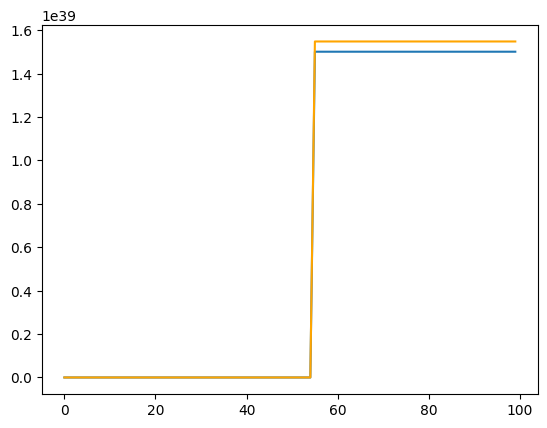

In [37]:
plt.plot(np.arange(len(LossList)),LossList)
plt.plot(np.arange(len(LossList2)),LossList2, c= "orange")

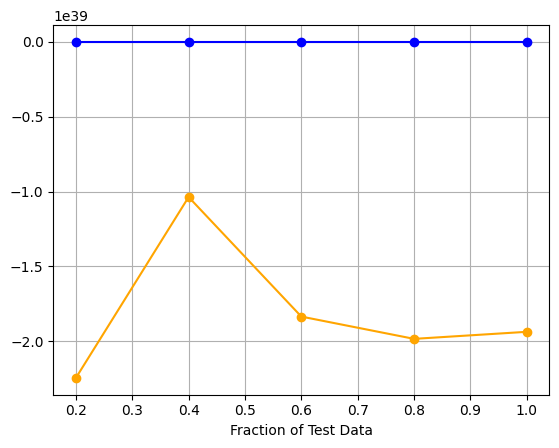

In [38]:
R2List = []
DataSize = []
RMSEList = []

for SizeOfData in range(1,5+1):
    PreviousSize = (SizeOfData - 1)/5
    SizeOfData = SizeOfData /5
    DataSize.append(SizeOfData)


    BatchX_Test = X_Test[int(len(X_Test)*PreviousSize):int(len(X_Test)*SizeOfData)]
    BatchY_Test = Y_Test[int(len(X_Test)*PreviousSize):int(len(Y_Test)*SizeOfData)]

    mean = np.mean(BatchY_Test)
    SStotalSumSquare = np.sum((BatchY_Test - mean)**2)

    MSE = lossfunc(co,Intercept,BatchX_Test,BatchY_Test)
    R2 = 1 - (MSE / ( SStotalSumSquare/ len(BatchY_Test)))


    R2List.append(R2)
    RMSEList.append(MSE**(1/2))

plt.plot(DataSize[:len(R2List)], R2List, marker='o', color="orange")
plt.plot(DataSize[:len(R2List)], RMSEList, marker='o', color="blue")

plt.xlabel('Fraction of Test Data')
plt.grid(True)
plt.show()


FITTING CHECK

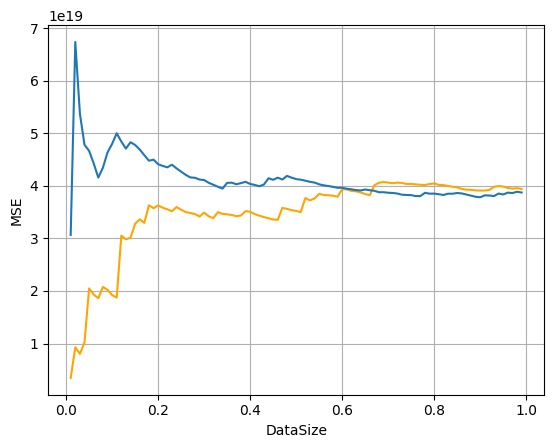

In [39]:
LossfuncTrain = []
LostfunTest = []
DataSize = []
for SizeOfData in range(1,100):
    SizeOfData = SizeOfData /100
    DataSize.append(SizeOfData)

    BatchX_Train = X_Train[0:int(len(X_Train)*SizeOfData)]
    BatchY_Train = Y_Train[0:int(len(Y_Train)*SizeOfData)]
    LossfuncTrain.append(lossfunc(co,Intercept,BatchX_Train,BatchY_Train)**(1/2))

    BatchX_Test = X_Test[0:int(len(X_Test)*SizeOfData)]
    BatchY_Test = Y_Test[0:int(len(Y_Test)*SizeOfData)]
    LostfunTest.append(lossfunc(co,Intercept,BatchX_Test,BatchY_Test)**(1/2))

plt.xlabel("DataSize")
plt.ylabel("MSE")
plt.plot(DataSize,LostfunTest,c= "orange")
plt.plot(DataSize,LossfuncTrain)
plt.grid(True)


#not over fitting